---
title: "Electromagnetic Waves — Level 2"
short_title: "08 EM Waves"
numbering:
  heading_2: true
  equation: true
---

# Electromagnetic Waves

:::{seealso} Math for this topic
- [E-M3: Waves and Fourier transforms](../math/03-waves-fourier-transforms.ipynb)
- [M4: Linear ODEs, Fourier series and transforms](../../level2-book/math/04-linear-odes-fourier.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 30–31 | Speed of light, intensity, polarization in words |
| **2** | **Griffiths, ch. 9** | **Derive the wave equation; reflection and transmission at boundaries; dispersion** |
| 3 | Jackson, ch. 7–8 | Waveguides, cavities, complex permittivity, dispersion relations |

The new skill at this level: deriving light from Maxwell's equations and computing what happens at boundaries between media

Math for this topic: E-M3, waves and Fourier transforms (and mechanics M4 for complex exponentials).
:::

Workbook example ladder: plane-wave intensity → Fresnel equations → modes in a rectangular waveguide. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## Waves from Maxwell's Equations

In empty space ($\rho = 0$, $\vec{J} = \vec{0}$), take the curl of Faraday's law and use the curl-curl identity (E-M1) with $\nabla\cdot\vec{E} = 0$:

$$
\nabla\times(\nabla\times\vec{E}) = -\nabla^2\vec{E} = -\frac{\partial}{\partial t}(\nabla\times\vec{B}) = -\mu_0\epsilon_0\frac{\partial^2\vec{E}}{\partial t^2} .
$$

So each component of $\vec{E}$, and likewise of $\vec{B}$, obeys the wave equation (E-M3) with speed

$$
c = \frac{1}{\sqrt{\mu_0\epsilon_0}} = 2.998\times10^8\ \text{m/s} .
$$ (eq-speed-of-light)

Maxwell computed this number from electrical measurements, saw that it matched the measured speed of light, and concluded that light is an electromagnetic wave.

## Plane Waves

Try a monochromatic plane wave, $\tilde{\vec{E}} = \tilde{\vec{E}}_0e^{i(\vec{k}\cdot\vec{r} - \omega t)}$, $\tilde{\vec{B}} = \tilde{\vec{B}}_0e^{i(\vec{k}\cdot\vec{r} - \omega t)}$. With $\nabla\to i\vec{k}$ and $\partial_t\to -i\omega$ (E-M3), Maxwell's equations become algebra:

$$
\vec{k}\cdot\tilde{\vec{E}}_0 = 0, \qquad \vec{k}\cdot\tilde{\vec{B}}_0 = 0, \qquad \tilde{\vec{B}}_0 = \frac1\omega\,\vec{k}\times\tilde{\vec{E}}_0, \qquad \omega = ck .
$$

So electromagnetic waves are **transverse**; $\vec{E}$, $\vec{B}$ and $\vec{k}$ form a right-handed set; the fields are in phase; and $B_0 = E_0/c$.

### Polarization

The direction of $\vec{E}$ is the **polarization**. For a wave along $z$, write $\tilde{\vec{E}}_0 = E_x\hat{x} + E_ye^{i\delta}\hat{y}$. The tip of the real $\vec{E}$ vector traces:

- a line if $\delta = 0$ or $\pi$ (**linear**),
- a circle if $E_x = E_y$ and $\delta = \pm\pi/2$ (**circular**),
- an ellipse otherwise.

These are the Lissajous figures of the oscillations notes, at equal frequencies.

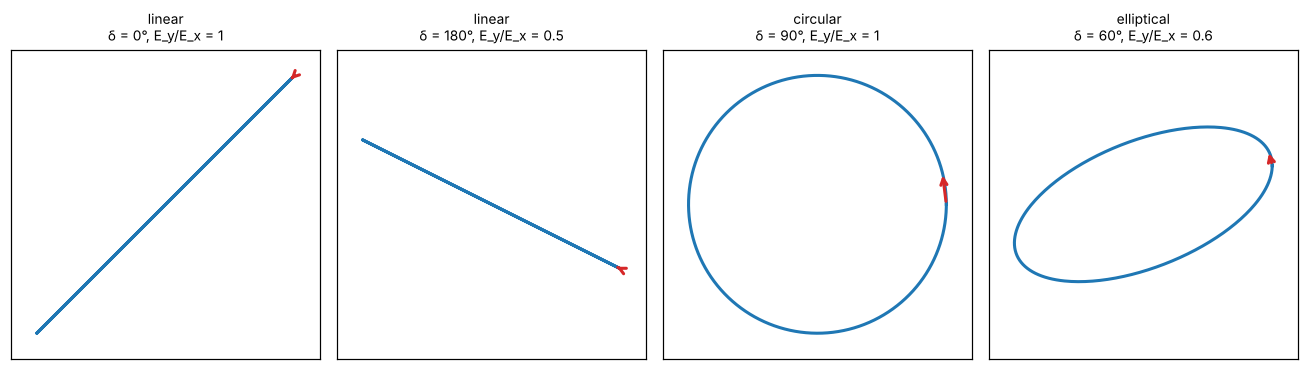

In [2]:
#| label: fig-polarization
#| caption: Path traced by the tip of E at a fixed point as a wave passes, for several amplitude ratios and phase differences δ between the x and y components.
t = np.linspace(0, 2 * np.pi, 300)
cases = [(1, 1, 0, "linear"), (1, 0.5, np.pi, "linear"), (1, 1, np.pi / 2, "circular"), (1, 0.6, np.pi / 3, "elliptical")]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, (ex, ey, d, name) in zip(axes, cases):
    ax.plot(ex * np.cos(t), ey * np.cos(t - d), lw=2)
    ax.annotate("", xy=(ex * np.cos(0.25), ey * np.cos(0.25 - d)), xytext=(ex, ey * np.cos(-d)),
                arrowprops=dict(arrowstyle="->", color="tab:red", lw=2))
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name}\nδ = {np.degrees(d):.0f}°, E_y/E_x = {ey}", fontsize=9)
plt.tight_layout(); plt.show()

### Energy and momentum

For a plane wave the electric and magnetic energy densities are equal, $\tfrac{\epsilon_0}{2}E^2 = \frac{1}{2\mu_0}B^2$, and the Poynting vector points along $\vec{k}$ with magnitude $c\,u$. Averaged over a cycle, the **intensity** is

$$
I = \langle S\rangle = \tfrac12c\epsilon_0E_0^2 .
$$

The wave also carries momentum density $u/c$, so absorbing it exerts a **radiation pressure** $P = I/c$ (twice that for perfect reflection). Sunlight at Earth has $I\approx1361$ W/m², giving $E_0\approx1000$ V/m and a pressure of about $4.5\ \mu$Pa, small but enough to steer spacecraft and drive solar sails.

In [3]:
I_sun = 1361.0
E0 = np.sqrt(2 * I_sun / (c * eps0))
print(f"E0 = {E0:.0f} V/m, B0 = {E0 / c * 1e6:.2f} μT, pressure (absorbed) = {I_sun / c * 1e6:.2f} μPa")

E0 = 1013 V/m, B0 = 3.38 μT, pressure (absorbed) = 4.54 μPa


### Exercises

1. A laser pointer emits 5 mW in a beam of 1 mm² cross-section. Find the intensity, the peak electric field, and the force on a perfect mirror that reflects the beam.
2. Write the real $\vec{E}$ and $\vec{B}$ for a wave of amplitude $E_0$ traveling in the $-\hat{y}$ direction, polarized along $\hat{z}$.
3. Show that a circularly polarized wave is a superposition of two linearly polarized waves, and that a linearly polarized wave is a superposition of two circular ones.

:::{dropdown} Hints
1. $I = P/A$; $E_0 = \sqrt{2I/c\epsilon_0}$; reflection gives force $2P/c$.
2. $\vec{k} = -k\hat{y}$ and $\vec{B}_0 = \frac{1}{\omega}\vec{k}\times\vec{E}_0$.
3. Add $\hat{x} + i\hat{y}$ and $\hat{x} - i\hat{y}$.
:::

:::{dropdown} Answers
1. $I = 5000$ W/m², $E_0\approx1.9$ kV/m, $F = 2(5\times10^{-3})/c\approx3.3\times10^{-11}$ N.
2. $\vec{E} = E_0\cos(-ky - \omega t)\hat{z} = E_0\cos(ky + \omega t)\hat{z}$ and $\vec{B} = -\frac{E_0}{c}\cos(ky + \omega t)\hat{x}$.
3. $(\hat{x} + i\hat{y})$ is circular and is the sum of two linear components $90^\circ$ out of phase; conversely $\hat{x} = \tfrac12[(\hat{x} + i\hat{y}) + (\hat{x} - i\hat{y})]$.
:::

## Waves in Linear Media and at Boundaries

In a linear medium without free charges, $\epsilon_0\to\epsilon$ and $\mu_0\to\mu$, so waves travel at $v = 1/\sqrt{\epsilon\mu} = c/n$, with **index of refraction** $n = \sqrt{\epsilon_r\mu_r}\approx\sqrt{\epsilon_r}$ for most materials.

At a boundary between two media, the boundary conditions (continuity of tangential $\vec{E}$ and $\vec{H}$, and of normal $\vec{D}$ and $\vec{B}$) must hold at every point and time. Matching the phases along the surface forces:

- the **law of reflection**: angle of reflection equals angle of incidence;
- **Snell's law**: $n_1\sin\theta_I = n_2\sin\theta_T$;
- equal frequencies on both sides.

Matching the amplitudes gives the **Fresnel equations**. For nonmagnetic media, the reflected amplitude ratios for the two polarizations are

$$
r_s = \frac{n_1\cos\theta_I - n_2\cos\theta_T}{n_1\cos\theta_I + n_2\cos\theta_T}\ (\text{E perpendicular to the plane of incidence}), \qquad
r_p = \frac{n_2\cos\theta_I - n_1\cos\theta_T}{n_2\cos\theta_I + n_1\cos\theta_T}\ (\text{E in the plane}),
$$ (eq-fresnel)

and the reflected fraction of the power is $R = r^2$. At normal incidence both reduce to $R = \left(\frac{n_1 - n_2}{n_1 + n_2}\right)^2$, about $4\%$ for air to glass.

Two angles are special:

- **Brewster's angle**, $\tan\theta_B = n_2/n_1$: $r_p = 0$, so reflected light is purely $s$-polarized. Polarized sunglasses exploit this to block glare.
- **Critical angle**, $\sin\theta_c = n_2/n_1$ (only when $n_1 > n_2$): beyond it there is no transmitted wave and reflection is total. Optical fibers work this way.

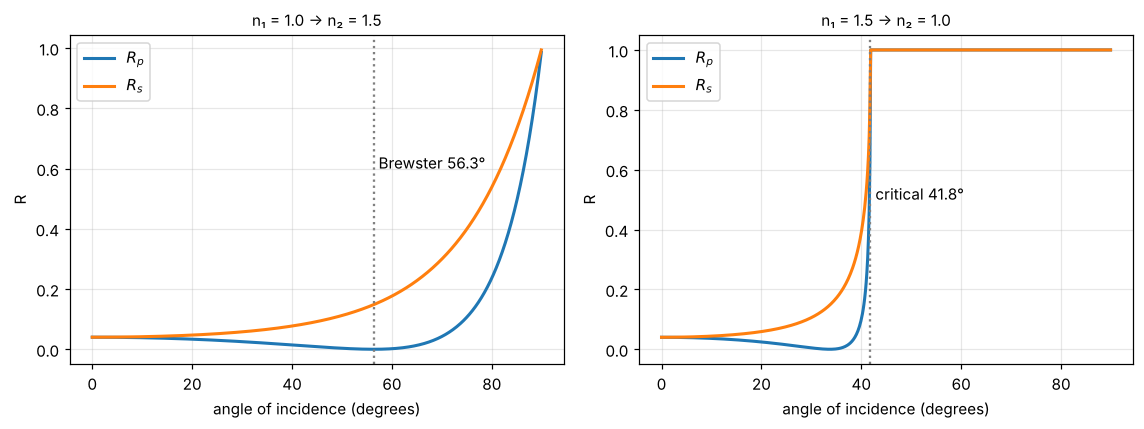

In [4]:
#| label: fig-fresnel
#| caption: "Reflected fraction of power versus angle of incidence. Left, air to glass (n = 1.5): R_p drops to zero at Brewster's angle (56.3°). Right, glass to air: total internal reflection beyond the critical angle (41.8°)."
def fresnel(n1, n2, thI):
    sinT = n1 / n2 * np.sin(thI)
    ok = sinT <= 1
    cosT = np.sqrt(np.clip(1 - sinT**2, 0, None))
    cosI = np.cos(thI)
    rs = (n1 * cosI - n2 * cosT) / (n1 * cosI + n2 * cosT)
    rp = (n2 * cosI - n1 * cosT) / (n2 * cosI + n1 * cosT)
    return np.where(ok, rp**2, 1.0), np.where(ok, rs**2, 1.0)
th = np.radians(np.linspace(0, 89.9, 600))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for ax, (n1, n2) in zip(axes, [(1.0, 1.5), (1.5, 1.0)]):
    Rpar, Rperp = fresnel(n1, n2, th)
    ax.plot(np.degrees(th), Rpar, lw=2, label=r"$R_p$"); ax.plot(np.degrees(th), Rperp, lw=2, label=r"$R_s$")
    if n2 > n1:
        tb = np.degrees(np.arctan(n2 / n1)); ax.axvline(tb, color="gray", ls=":"); ax.text(tb + 1, 0.6, f"Brewster {tb:.1f}°")
    else:
        tc = np.degrees(np.arcsin(n2 / n1)); ax.axvline(tc, color="gray", ls=":"); ax.text(tc + 1, 0.5, f"critical {tc:.1f}°")
    ax.set_xlabel("angle of incidence (degrees)"); ax.set_ylabel("R"); ax.set_title(f"n₁ = {n1} → n₂ = {n2}", fontsize=10); ax.legend()
plt.tight_layout(); plt.show()

## Waves in Conductors

In a conductor with conductivity $\sigma$, the current $\vec{J} = \sigma\vec{E}$ enters the Ampère–Maxwell law, and the wave equation acquires a damping term. A plane wave becomes $e^{-\kappa z}e^{i(kz - \omega t)}$, decaying as it penetrates. In a good conductor ($\sigma\gg\omega\epsilon$) the decay length, the **skin depth**, is

$$
\delta = \frac1\kappa\approx\sqrt{\frac{2}{\omega\mu\sigma}} .
$$ (eq-skin-depth)

High frequencies stay near the surface. That is why metals reflect light, why AC current crowds to the outside of thick wires, and why submarines communicate at very low frequencies.

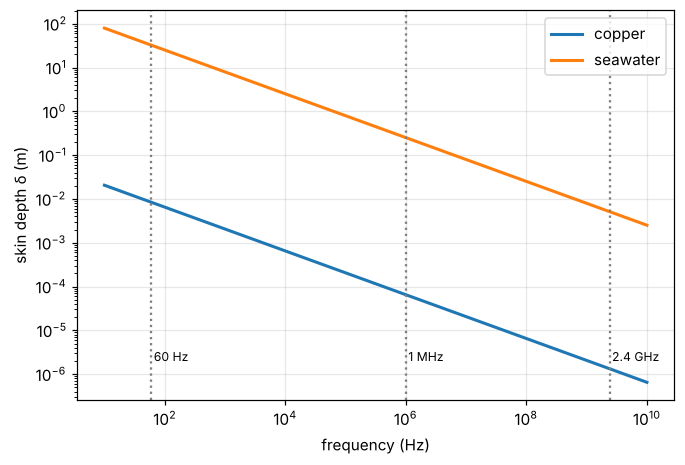

copper at 60 Hz: 8.4 mm


In [5]:
#| label: fig-skin-depth
#| caption: Skin depth versus frequency for copper (σ = 5.96 × 10⁷ S/m) and seawater (σ ≈ 4 S/m). At 60 Hz the current in copper fills about the outer 8 mm; at microwave frequencies only a micron; seawater blocks all but very low frequencies within meters.
f = np.logspace(1, 10, 300)
fig, ax = plt.subplots()
for sig_, lab in [(5.96e7, "copper"), (4.0, "seawater")]:
    ax.loglog(f, np.sqrt(2 / (2 * np.pi * f * mu0 * sig_)), lw=2, label=lab)
for f0, lab in [(60, "60 Hz"), (1e6, "1 MHz"), (2.4e9, "2.4 GHz")]:
    ax.axvline(f0, color="gray", ls=":"); ax.text(f0 * 1.1, 2e-6, lab, fontsize=8)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("skin depth δ (m)"); ax.legend(); plt.show()
print(f"copper at 60 Hz: {np.sqrt(2 / (2 * np.pi * 60 * mu0 * 5.96e7)) * 1e3:.1f} mm")

## Dispersion

In real materials $\epsilon$ depends on frequency, so different colors travel at different speeds (prisms, rainbows, pulse spreading in fibers). A simple model treats each bound electron as a damped oscillator (oscillations notes) with natural frequency $\omega_0$ and damping $\gamma$, driven by the wave's field. Its induced dipole gives

$$
n(\omega)\approx1 + \frac{Nq^2}{2m\epsilon_0}\,\frac{1}{\omega_0^2 - \omega^2 - i\gamma\omega} .
$$

The real part of $n$ rises with $\omega$ below the resonance (**normal dispersion**, the reason blue light bends more than red in glass) and falls through the resonance (**anomalous dispersion**), where the imaginary part peaks and the material **absorbs**. Pulses move at the group velocity $d\omega/dk$ (E-M3), not the phase velocity.

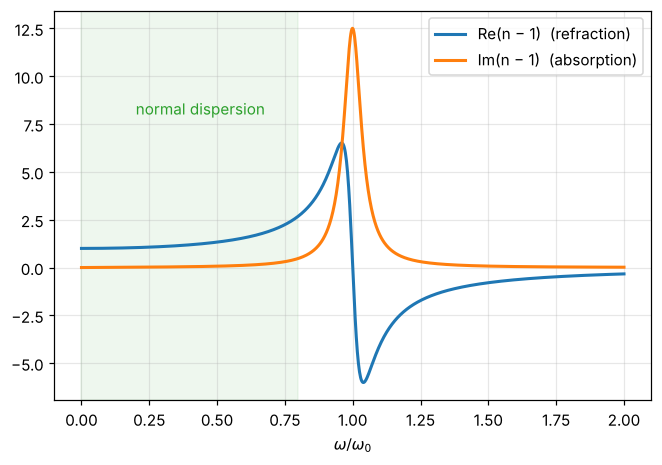

In [6]:
#| label: fig-dispersion-model
#| caption: Real and imaginary parts of n − 1 for a single damped-oscillator resonance (arbitrary units). Away from resonance, Re n rises with frequency (normal dispersion); near it, Re n falls and Im n, the absorption, peaks.
w = np.linspace(0, 2, 1000); w0, gam = 1.0, 0.08
chi = 1 / (w0**2 - w**2 - 1j * gam * w)
fig, ax = plt.subplots()
ax.plot(w, chi.real, lw=2, label="Re(n − 1)  (refraction)")
ax.plot(w, chi.imag, lw=2, label="Im(n − 1)  (absorption)")
ax.axvspan(0.0, 0.8, color="tab:green", alpha=0.08); ax.text(0.2, 8, "normal dispersion", color="tab:green")
ax.set_xlabel(r"$\omega/\omega_0$"); ax.legend(); plt.show()

### Exercises

1. Find the reflected fraction of light at normal incidence from air to water ($n = 1.33$) and from air to diamond ($n = 2.42$).
2. Find Brewster's angle for light going from air into water.
3. How thick must a copper shield be to reduce a 1 MHz field by a factor of $10^3$?

:::{dropdown} Hints
1. $R = \left(\frac{n - 1}{n + 1}\right)^2$.
2. $\tan\theta_B = n_2/n_1$.
3. The field falls as $e^{-z/\delta}$; solve $e^{-z/\delta} = 10^{-3}$.
:::

:::{dropdown} Answers
1. Water $\approx2.0\%$; diamond $\approx17\%$, part of why diamonds sparkle.
2. $\theta_B = \arctan1.33\approx53^\circ$.
3. $\delta\approx65\ \mu$m at 1 MHz, so $z = \delta\ln1000\approx0.45$ mm.
:::

## Summary

- Maxwell's equations in vacuum give transverse waves at $c = 1/\sqrt{\mu_0\epsilon_0}$, with $\vec{E}\perp\vec{B}\perp\vec{k}$ and $B_0 = E_0/c$.
- Polarization can be linear, circular or elliptical; intensity is $\tfrac12c\epsilon_0E_0^2$ and radiation pressure $I/c$.
- At boundaries, phase matching gives reflection and Snell's laws; amplitude matching gives the Fresnel equations, Brewster's angle and total internal reflection.
- In conductors, waves die off within the skin depth $\sqrt{2/\omega\mu\sigma}$.
- Frequency-dependent $\epsilon$ gives dispersion and absorption near resonances.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.